# 📊 La Transición del Mercado (Evolución Temporal)

### ¿Cómo evolucionó la participación y el peso económico de las casas de apuestas respecto a los sponsors tradicionales (bancos, financieras, etc.) entre 2019 y 2025?

---

**Clubes analizados:**
*   Internacional
*   Corinthians
*   Flamengo
*   Palmeiras
*   São Paulo
*   Grêmio
*   Santos FC
*   Fluminense
*   Vasco da Gama

## 💾 Inicio de integración de bases y datos financieros

Antes de iniciar nuestro análisis, se inspecciona la base "balances_y_sponsors_2019_2029.csv".


In [ ]:
import pandas as pd
import os
from pathlib import Path

# ============================================================================== 
# LECTURA E INTEGRACIÓN DE DATOS (Corinthians e Internacional)
# ============================================================================== 
# Se llama al archivo base
file_name = (
    Path.cwd().parent
    / "BaseDatos"
    / "balances_y_sponsors_2019_2025.csv"
)

df = pd.read_csv(file_name, encoding="utf-8")
df.columns = df.columns.str.strip() # Eliminamos espacios accidentales en los nombres de las columnas

# Defino columnas de interes para el análisis
columnas = [
    "club", "año", "ingreso_operativo_bruto", "ingreso_recurrente",
    "ingreso_comercial_total", "patrocinio_uniforme", "sponsor_bet_principal",
    "tipo_presencia_bet", "ingreso_sponsor_bet", "contrato_bet_anualizado",
    "pasivo_derechos_imagen", "pasivo_circulante", "superavit_o_deficit",
]

# Datos financieros oficiales extraídos de los reportes
datos_corinthians = [
    ["Corinthians", 2019, 426.40, 350.00, 73.30, 50.00, "Marjosports", "Secundario / Transición", 4.50, 4.50, 48.50, 967.30, -195.50],
    ["Corinthians", 2020, 438.20, 360.00, 71.10, 52.00, "Galera.bet", "Secundario / Transición", 8.00, 8.00, 121.40, 847.20, -123.30],
    ["Corinthians", 2021, 447.80, 390.00, 126.30, 84.00, "Galera.bet", "Secundario / Transición", 8.00, 8.00, 47.20, 962.30, 5.70],
    ["Corinthians", 2022, 687.00, 633.00, 93.60, 70.00, "Galera / Pixbet", "Secundario / Transición", 15.00, 15.00, 66.70, 824.30, 15.40],
    ["Corinthians", 2023, 872.40, 686.00, 128.60, 95.00, "Pixbet / Galera", "Secundario / Transición", 20.00, 20.00, 114.00, 1072.30, 1.20],
    ["Corinthians", 2024, 1114.90, 777.00, 264.50, 217.40, "VaiDeBet / Esportes da Sorte", "Máster Principal", 111.50, 111.50, 115.00, 1250.00, -9.50],
    ["Corinthians", 2025, 971.00, 787.00, 252.20, 124.80, "Esportes da Sorte / Viva da Sorte", "Máster Principal", 103.00, 103.00, 120.00, 979.80, 139.00],
]

datos_internacional = [
    ["Internacional", 2019, 441.34, 362.00, 55.20, 39.72, "Nenhum", "Sin Bet", 0.00, 0.00, 18.50, 474.05, -3.02],
    ["Internacional", 2020, 281.00, 225.00, 42.10, 29.60, "Betsul", "Secundario / Transición", 2.00, 2.00, 21.30, 463.32, -91.89],
    ["Internacional", 2021, 380.00, 310.00, 48.50, 32.30, "Betsul", "Secundario / Transición", 3.00, 3.00, 19.80, 475.53, 0.79],
    ["Internacional", 2022, 466.00, 355.00, 58.20, 38.47, "EstrelaBet", "Secundario / Transición", 5.00, 5.00, 22.40, 457.45, 1.03],
    ["Internacional", 2023, 553.00, 415.00, 88.50, 57.39, "EstrelaBet", "Secundario / Transición", 12.00, 12.00, 23.80, 478.47, 170.38],
    ["Internacional", 2024, 510.00, 398.00, 95.00, 62.65, "EstrelaBet", "Secundario / Transición", 15.00, 15.00, 23.84, 610.71, -34.50],
    ["Internacional", 2025, 682.00, 469.89, 245.00, 83.04, "EstrelaBet / Betano", "Máster Principal", 35.00, 35.00, 26.17, 606.92, 8.97],
]

# Excluimos posibles filas repetidas de la base original y anexamos las listas manuales
df_base = df[~df["club"].isin(["Corinthians", "Internacional"])].copy()
df_explicitos = pd.DataFrame(datos_corinthians + datos_internacional, columns=columnas)
df_completo = pd.concat([df_base, df_explicitos], ignore_index=True)


In [ ]:
# LIMPIEZA DE NULOS Y NORMALIZACIÓN
# =========================================================================
# Aseguramos que la columna 'año' sea un número entero (Int64)
df_completo["año"] = pd.to_numeric(df_completo["año"], errors="coerce").astype('Int64')

# Normalizamos las columnas contables forzándolas a formato numérico (float)
columnas_numericas = [
    "ingreso_operativo_bruto", "ingreso_recurrente", "ingreso_comercial_total",
    "patrocinio_uniforme", "ingreso_sponsor_bet", "contrato_bet_anualizado",
    "pasivo_derechos_imagen", "pasivo_circulante", "superavit_o_deficit",
]
for columna in columnas_numericas:
    df_completo[columna] = pd.to_numeric(df_completo[columna], errors="coerce")

# Calculamos los ingresos puramente tradicionales restando lo aportado por los sponsors bet
df_completo["patrocinio_tradicional"] = df_completo["patrocinio_uniforme"] - df_completo["ingreso_sponsor_bet"]


# ============================================================================== 
# EVOLUCIÓN CONSOLIDADA Y EXPORTACIÓN
# ============================================================================== 
# Agrupamos por año para observar cómo cambia el mercado en todos los clubes combinados
evolucion = (
    df_completo.groupby("año")
    .agg(
        patrocinio_total_M=("patrocinio_uniforme", "sum"),
        ingresos_bets_M=("ingreso_sponsor_bet", "sum"),
        ingresos_tradicionales_M=("patrocinio_tradicional", "sum"),
        ingreso_comercial_total_M=("ingreso_comercial_total", "sum"),
    )
    .reset_index()
    .sort_values("año")
)

# Calculamos el porcentaje de penetración en el mercado (share %)
base_porcentaje = evolucion["patrocinio_total_M"].replace(0, pd.NA) # Evitamos dividir por cero
evolucion["share_bets_%"] = evolucion["ingresos_bets_M"].div(base_porcentaje).mul(100).fillna(0)
evolucion["share_tradicional_%"] = evolucion["ingresos_tradicionales_M"].div(base_porcentaje).mul(100).fillna(0)

# Exportamos la base final limpia y con todos los datos integrados
df_completo.to_csv("balance_sponsor_completo.csv", index=False)

# Mostramos el resultado consolidado
print("EVOLUCIÓN CONSOLIDADA: CASAS DE APUESTAS VS. SPONSORS TRADICIONALES")
print(evolucion.round(2).to_string(index=False))

EVOLUCIÓN CONSOLIDADA: CASAS DE APUESTAS VS. SPONSORS TRADICIONALES
 año  patrocinio_total_M  ingresos_bets_M  ingresos_tradicionales_M  ingreso_comercial_total_M  share_bets_%  share_tradicional_%
2019              359.49              7.5                    351.99                     494.45          2.09                97.91
2020              385.68             13.0                    372.68                     517.52          3.37                96.63
2021              528.61             62.5                    466.11                     811.40         11.82                88.18
2022              580.16            108.1                    472.06                     894.68         18.63                81.37
2023              717.24            147.5                    569.74                    1130.13         20.56                79.44
2024              993.03            459.5                    533.53                    1490.17         46.27                53.73
2025             1177.

## 📈 Inicio del Análisis Visual

En esta sección, procederemos a la generación de los gráficos. Nuestro enfoque principal será la comparación directa entre el impacto económico de las **Casas de Apuestas (Bets)** frente a los **Sponsors Tradicionales**.

### **GRÁFICO 1 - VOLUMEN DE PATROCINIO**

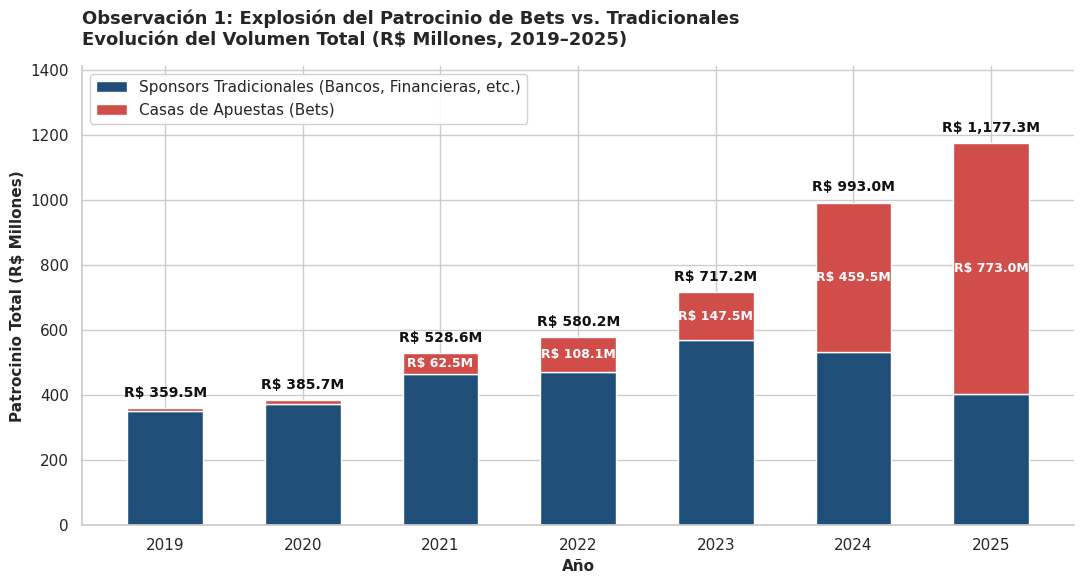

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'left': 'Observación 1: Explosión del Patrocinio de Bets vs. Tradicionales\nEvolución del Volumen Total (R$ Millones, 2019–2025)'}, xlabel='Año', ylabel='Patrocinio Total (R$ Millones)'>)

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración visual global para los gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# ==============================================================================
# GRÁFICO 1 - VOLUMEN DE PATROCINIO (BARRAS)
# ==============================================================================
def analisis_patrocinio_vs_tradicionales(df, guardar_path=None, mostrar=True):
    """
    Genera un gráfico de barras apiladas mostrando el volumen total de patrocinio
    (Tradicionales vs Bets) en millones de R$.
    """
    # Agrupamos los datos por año calculando las sumas correspondientes
    df_volumen = df.groupby('año')[['ingreso_sponsor_bet', 'patrocinio_tradicional', 'patrocinio_uniforme']].sum().reset_index()
    
    fig, ax = plt.subplots(figsize=(11, 6))

    # Barras apiladas
    ax.bar(df_volumen['año'], df_volumen['patrocinio_tradicional'], 
           label='Sponsors Tradicionales (Bancos, Financieras, etc.)', color='#1F4E79', width=0.55)
    
    ax.bar(df_volumen['año'], df_volumen['ingreso_sponsor_bet'], 
           bottom=df_volumen['patrocinio_tradicional'], 
           label='Casas de Apuestas (Bets)', color="#D14D49", width=0.55)

    # Títulos y formato
    ax.set_title('Observación 1: Explosión del Patrocinio de Bets vs. Tradicionales\n'
                 'Evolución del Volumen Total (R$ Millones, 2019–2025)', fontsize=13, fontweight='bold', loc='left', pad=15)
    ax.set_xlabel('Año', fontsize=11, fontweight='bold')
    ax.set_ylabel('Patrocinio Total (R$ Millones)', fontsize=11, fontweight='bold')
    ax.set_xticks(df_volumen['año'])
    ax.set_ylim(0, df_volumen['patrocinio_uniforme'].max() * 1.2)

    # Anotaciones numéricas
    for _, row in df_volumen.iterrows():
        ax.text(row['año'], row['patrocinio_uniforme'] + 25, f"R$ {row['patrocinio_uniforme']:,.1f}M",
                ha='center', va='bottom', fontweight='bold', fontsize=10, color='#111111')
        if row['ingreso_sponsor_bet'] > 40:
            ax.text(row['año'], row['patrocinio_tradicional'] + (row['ingreso_sponsor_bet'] / 2), 
                    f"R$ {row['ingreso_sponsor_bet']:,.1f}M", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

    sns.despine()
    ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
    plt.tight_layout()

    if guardar_path:
        fig.savefig(guardar_path, dpi=200, bbox_inches='tight')
    if mostrar:
        plt.show()
    return fig, ax

analisis_patrocinio_vs_tradicionales(df_completo)

In [16]:
# Analizamos la fila donde el año es 2025 y seleccionamos la columna 'share_bets_%'
share_2025 = evolucion.loc[evolucion['año'] == 2025, 'share_bets_%'].values[0]

print("---ESTADÍSTICA 1: Share de Mercado ---")
print(f"El porcentaje exacto de las casas de apuestas en 2025 es: {share_2025:.2f}%")


---ESTADÍSTICA 1: Share de Mercado ---
El porcentaje exacto de las casas de apuestas en 2025 es: 65.66%


### 🚨 Hallazgo Principal: Dominio de Mercado en 2025

* **Métrica analizada:** Share de Mercado de Casas de Apuestas (`share_bets_%`)
* **Año de referencia:** `2025`
* **Porcentaje exacto:** **`65.66%`**

> **Conclusión:** 
> De un inicio marginal del **2.09%** en 2019, el sector de las apuestas pasó a controlar más de la mitad del mercado en 2024 (46.27%) y alcanzó su pico histórico de **65.66%** en 2025, desplazando por completo a la banca y financieras tradicionales.

---

### **GRÁFICO 2 - PARTICIPACIÓN DE MERCADO**

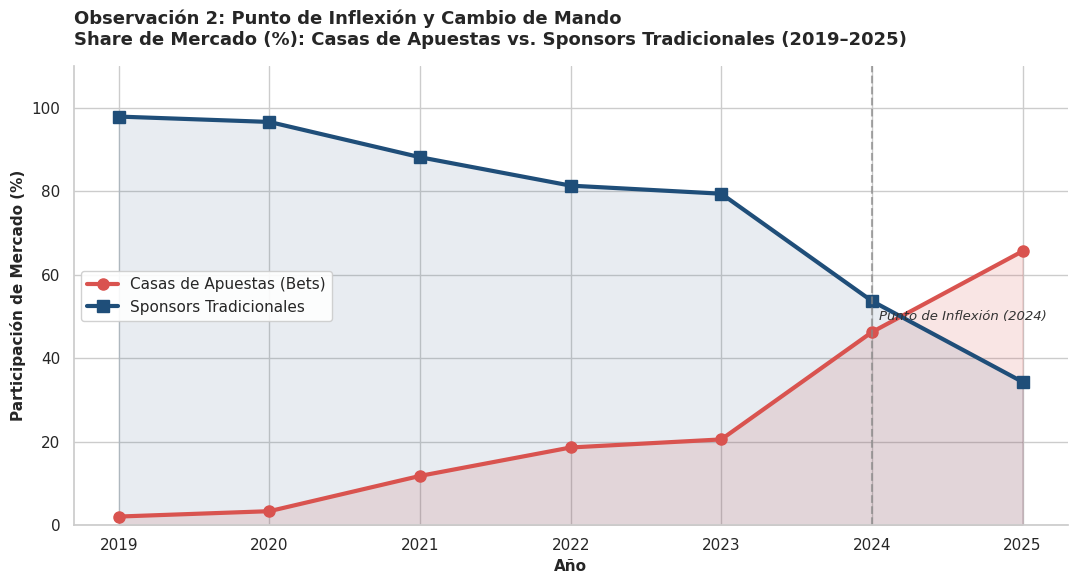

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'left': 'Observación 2: Punto de Inflexión y Cambio de Mando\nShare de Mercado (%): Casas de Apuestas vs. Sponsors Tradicionales (2019–2025)'}, xlabel='Año', ylabel='Participación de Mercado (%)'>)

In [ ]:
def analisis_participacion_bets_vs_tradicionales(df, guardar_path=None, mostrar=True):
    """
    Genera un gráfico de líneas comparando el porcentaje de participación (Share %)
    de las Casas de Apuestas vs Sponsors Tradicionales.
    """
    # Calculamos el Share % dinámicamente
    evolucion = df.groupby('año')[['ingreso_sponsor_bet', 'patrocinio_tradicional', 'patrocinio_uniforme']].sum().reset_index()
    evolucion['share_bets_%'] = (evolucion['ingreso_sponsor_bet'] / evolucion['patrocinio_uniforme']) * 100
    evolucion['share_tradicional_%'] = (evolucion['patrocinio_tradicional'] / evolucion['patrocinio_uniforme']) * 100

    fig, ax = plt.subplots(figsize=(11, 6))

    # Trazado de líneas
    ax.plot(evolucion['año'], evolucion['share_bets_%'], marker='o', linewidth=3, markersize=8, color='#D9534F', label='Casas de Apuestas (Bets)')
    ax.plot(evolucion['año'], evolucion['share_tradicional_%'], marker='s', linewidth=3, markersize=8, color='#1F4E79', label='Sponsors Tradicionales')

    ax.fill_between(evolucion['año'], evolucion['share_bets_%'], color='#D9534F', alpha=0.15)
    ax.fill_between(evolucion['año'], evolucion['share_tradicional_%'], color='#1F4E79', alpha=0.1)

    # Detalle de inflexión
    ax.axvline(x=2024, color='#888888', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.text(2024.05, 50, 'Punto de Inflexión (2024)', fontsize=9.5, fontstyle='italic', color='#333333', va='center')

    ax.set_title('Observación 2: Punto de Inflexión y Cambio de Mando\n'
                 'Share de Mercado (%): Casas de Apuestas vs. Sponsors Tradicionales (2019–2025)', fontsize=13, fontweight='bold', loc='left', pad=15)
    ax.set_xlabel('Año', fontsize=11, fontweight='bold')
    ax.set_ylabel('Participación de Mercado (%)', fontsize=11, fontweight='bold')
    ax.set_xticks(evolucion['año'])
    ax.set_ylim(0, 110)

    sns.despine()
    ax.legend(loc='center left', frameon=True, facecolor='white', framealpha=0.9)
    plt.tight_layout()

    if guardar_path:
        fig.savefig(guardar_path, dpi=200, bbox_inches='tight')
    if mostrar:
        plt.show()
    return fig, ax

analisis_participacion_bets_vs_tradicionales(df_completo)

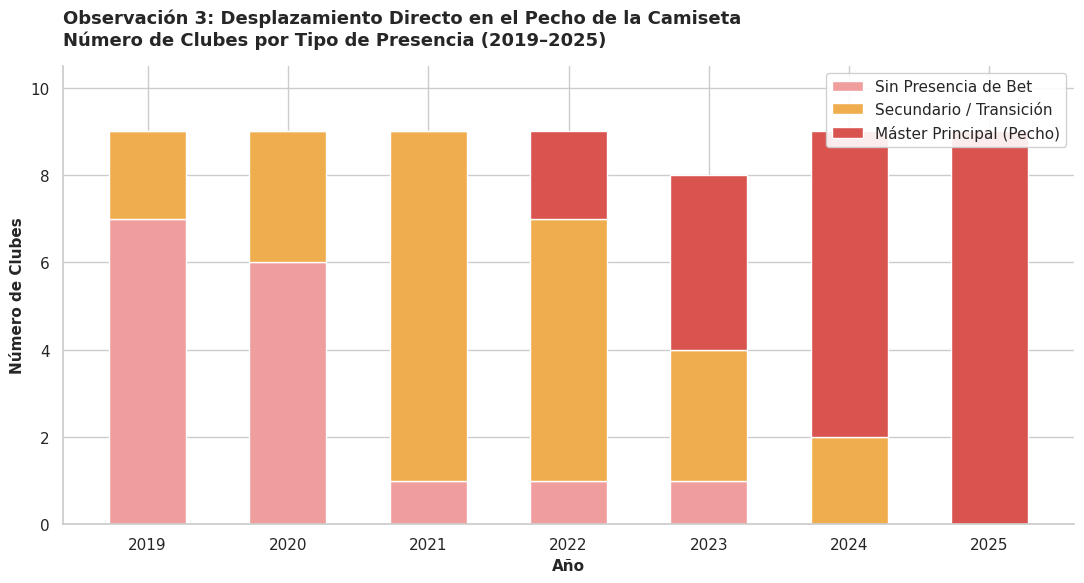

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'left': 'Observación 3: Desplazamiento Directo en el Pecho de la Camiseta\nNúmero de Clubes por Tipo de Presencia (2019–2025)'}, xlabel='Año', ylabel='Número de Clubes'>)

In [ ]:
def analisis_desplazamiento(df, guardar_path=None, mostrar=True):
    """
    Genera un gráfico de barras apiladas contando el número de clubes según el 
    tipo de presencia de las casas de apuestas en sus camisetas.
    """
    # Contamos la cantidad de cada tipo de presencia por año
    roles = df.groupby(['año', 'tipo_presencia_bet']).size().unstack(fill_value=0).reset_index()
    
    # Aseguramos que existan las 3 categorías aunque un año tenga 0
    for col in ['Sin Bet', 'Secundario / Transición', 'Máster Principal']:
        if col not in roles.columns:
            roles[col] = 0

    fig, ax = plt.subplots(figsize=(11, 6))

    b1 = ax.bar(roles['año'], roles['Sin Bet'], label='Sin Presencia de Bet', color="#EF9D9D", width=0.55)
    b2 = ax.bar(roles['año'], roles['Secundario / Transición'], bottom=roles['Sin Bet'], label='Secundario / Transición', color='#F0AD4E', width=0.55)
    b3 = ax.bar(roles['año'], roles['Máster Principal'], bottom=roles['Sin Bet'] + roles['Secundario / Transición'], label='Máster Principal (Pecho)', color='#D9534F', width=0.55)

    ax.set_title('Observación 3: Desplazamiento Directo en el Pecho de la Camiseta\n'
                 'Número de Clubes por Tipo de Presencia (2019–2025)', fontsize=13, fontweight='bold', loc='left', pad=15)
    ax.set_xlabel('Año', fontsize=11, fontweight='bold')
    ax.set_ylabel('Número de Clubes', fontsize=11, fontweight='bold')
    ax.set_xticks(roles['año'])
    ax.set_ylim(0, 10.5)

    sns.despine()
    ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    plt.tight_layout()

    if guardar_path:
        fig.savefig(guardar_path, dpi=200, bbox_inches='tight')
    if mostrar:
        plt.show()
    return fig, ax

analisis_desplazamiento(df_completo)

## 🧠 Conclusión Final: La Transición del Mercado (2019 - 2025)

El análisis de la evolución temporal revela un cambio de paradigma absoluto en la matriz de ingresos de los principales clubes brasileños. Entre 2019 y 2025, observamos tres fenómenos clave:

1. **Explosión del Volumen y Cambio de Mando (Share %):** En 2019, las casas de apuestas representaban un marginal 2.09% de los ingresos por patrocinio en las camisetas. Para 2025, esta cifra escaló violentamente hasta acaparar el **65.66% del mercado**, desplazando casi por completo a los sponsors tradicionales (bancos, automotrices y consumo masivo), quienes pasaron del 97.91% a solo el 34.34%.
2. **Punto de Inflexión (2023-2024):** El año 2024 marca la ruptura del mercado, donde el share de las "Bets" se dispara del 20.56% (2023) al 46.27%, preludio del dominio absoluto en 2025. Esto coincide temporalmente con los procesos de regulación y la inyección masiva de capital extranjero.
3. **Desplazamiento Directo en la Camiseta (Roles):** El análisis cualitativo valida el impacto económico. En 2019, ningún club tenía una casa de apuestas como "Máster Principal" en el pecho (7 no tenían y 2 lo tenían en posiciones secundarias). Para 2025, **la totalidad de la muestra (9 de 9 clubes)** ha cedido el espacio central de su indumentaria a las casas de apuestas, erradicando a los jugadores tradicionales de las zonas de mayor visibilidad.

**En resumen:** Las casas de apuestas no solo inyectaron nuevo capital, sino que ejecutaron una agresiva estrategia de sustitución, inflando los valores de mercado a niveles que los patrocinadores tradicionales ya no están dispuestos o no pueden igualar.